# Exploration probly

To-Do:
* Create index, solved 
* create different sections
    * sklearn
    * pytorch
    * respective links to docs (I'll do a section with links at the end)
    * examples with explanation for various commands
    * try out different samples
* find better place to store the jupyter notebook..., solved

## Important Imports


In [ ]:
from __future__ import annotations

# Active Learning - General
Her is a section for Active Learning. It should include links to important literature and papers, as well as websites with explanations to technical terms.

## Statistic Theory

## Neural Networks

## Deep Ensembles

# SkLearn
I'll include code snippets and trials for sklearn. I downloaded the extension via the vscode terminal with the command 'sudo apt-get install python3-sklearn python3-sklearn-lib python-sklearn-doc'. As you can see below, it worked well. :\) Currently unsure if that was even necessary.

In [1]:
from sklearn.ensemble import (
    RandomForestClassifier,
)  # what are ensembles? difference betw. ensembles and deep ensembles?

clf = RandomForestClassifier(random_state=0)  # what does random_state do? what does rfc do?
X = [
    [1, 2, 3],  # 2 samples, 3 features; what are these samples for? RFC?
    [11, 12, 13],
]
y = [0, 1]  # classes of each sample; why classes? for what?
clf.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

## Userguide example 
The following is from the online walkthrough userguide for probly. Until now (06.11.2026) no concrete idea what happens exactly with all those commands. But it works. :\)

In [ ]:
from sklearn.datasets import (
    make_moons,  # make_moons creates a sample of moons (or how they call it, interleafing half circles)
)
import torch
from torch import nn

from examples.utils.model import MLPClassifier
from examples.utils.plotting import plot_example_uncertainty
from probly.representer import representer
from probly.transformation import dropout

In [3]:
X, y = make_moons(n_samples=500, noise=0.05, random_state=1)
X_tensor = torch.from_numpy(X).float()
y_tensor = torch.from_numpy(y).long()

In [4]:
base_model = MLPClassifier()

dropout_model = dropout(
    base_model,
    p=0.5,  # zeroing probability (kept active at inference)
    predictor_type="logit_classifier",
    shared_mask=True,  # one mask per forward pass, shared across the batch
)

In [5]:
opt = torch.optim.Adam(dropout_model.parameters(), lr=1e-3)

dropout_model.train()
for _epoch in range(300):
    opt.zero_grad()
    out = dropout_model(X_tensor)
    loss = nn.functional.cross_entropy(out, y_tensor)
    loss.backward()
    opt.step()

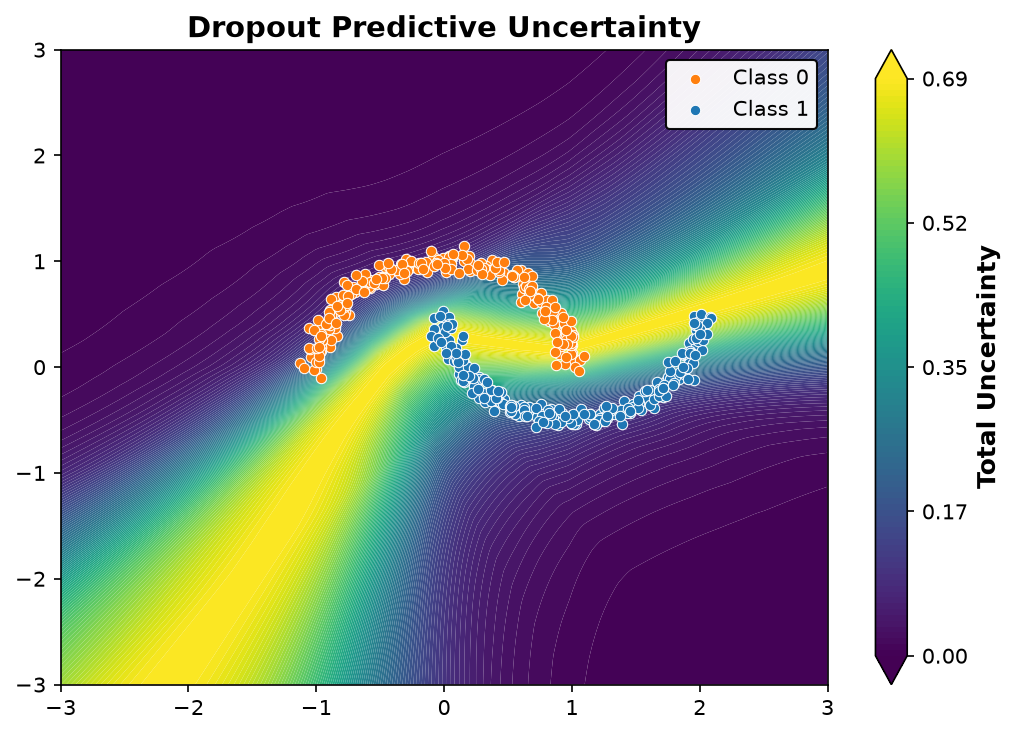

In [6]:
dropout_model.eval()
rep = representer(dropout_model, num_samples=400)

plot = plot_example_uncertainty(X, y, rep, title="Dropout Predictive Uncertainty", notion="total")
plot.show()

## AL example - sklearn 
The following is from the examples regarding active learning with probly from the user guide. Currently the user guide is really empty...

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from probly.evaluation.active_learning import (
    MarginSampling,
    RandomQuery,
    active_learning_steps,
    compute_accuracy,
    compute_ece,
    compute_nauc,
    from_dataset,
)

SEED = 42
INITIAL_SIZE = 30
QUERY_SIZE = 30
N_ITERATIONS = 15

The [__future__](https://docs.python.org/3/library/__future__.html) annotations 

In [8]:
X, y = load_digits(return_X_y=True)
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
)

In [9]:
strategies = {
    "Margin Sampling": MarginSampling(),
    "Random": RandomQuery(seed=SEED),
}

results: dict[str, dict] = {}

for name, strategy in strategies.items():
    pool = from_dataset(
        x_train,
        y_train,
        x_test,
        y_test,
        initial_size=INITIAL_SIZE,
        seed=SEED,
    )
    estimator = LogisticRegression(max_iter=1000, random_state=SEED)

    accuracies: list[float] = []
    eces: list[float] = []
    labeled_sizes: list[int] = []

    for state in active_learning_steps(
        pool,
        estimator,
        strategy,
        query_size=QUERY_SIZE,
        n_iterations=N_ITERATIONS,
    ):
        preds = state.estimator.predict(state.pool.x_test)
        probs = state.estimator.predict_proba(state.pool.x_test)
        accuracies.append(compute_accuracy(preds, state.pool.y_test))
        eces.append(compute_ece(probs, state.pool.y_test))
        labeled_sizes.append(state.pool.n_labeled)

    # NAUC (normalized area under the accuracy curve) summarizes how quickly
    # a strategy reaches good accuracy. Higher is better.
    nauc = compute_nauc(accuracies)
    results[name] = {
        "accuracies": accuracies,
        "eces": eces,
        "labeled_sizes": labeled_sizes,
    }
    print(f"{name:20s}  final acc: {accuracies[-1]:.3f}  ECE: {eces[-1]:.3f}  NAUC: {nauc:.3f}")

Margin Sampling       final acc: 0.975  ECE: 0.022  NAUC: 0.948
Random                final acc: 0.933  ECE: 0.030  NAUC: 0.925


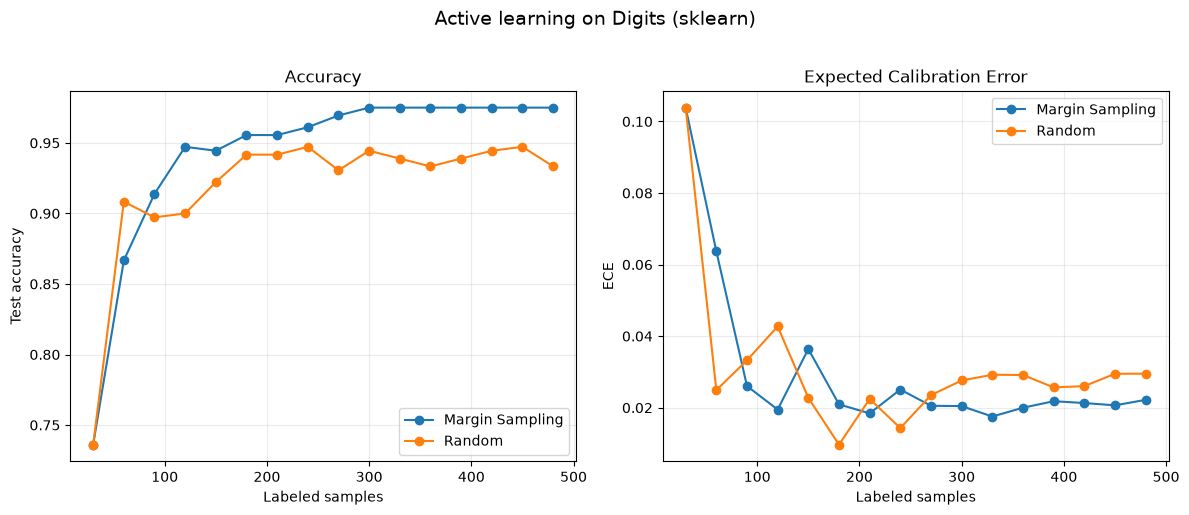

In [10]:
fig, (ax_acc, ax_ece) = plt.subplots(1, 2, figsize=(12, 5))

for name, data in results.items():
    ax_acc.plot(data["labeled_sizes"], data["accuracies"], marker="o", label=name)
    ax_ece.plot(data["labeled_sizes"], data["eces"], marker="o", label=name)

ax_acc.set_xlabel("Labeled samples")
ax_acc.set_ylabel("Test accuracy")
ax_acc.set_title("Accuracy")
ax_acc.legend()
ax_acc.grid(alpha=0.25)

ax_ece.set_xlabel("Labeled samples")
ax_ece.set_ylabel("ECE")
ax_ece.set_title("Expected Calibration Error")
ax_ece.legend()
ax_ece.grid(alpha=0.25)

fig.suptitle("Active learning on Digits (sklearn)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Pytorch
The following section is for experimenting with pytorch. It includes samples from the userguide.
[Link to pytorch examples by pytorch](https://docs.pytorch.org/tutorials/recipes_index.html)

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import torch
from torch import nn

from probly.evaluation.active_learning import (
    BADGEQuery,
    MarginSampling,
    RandomQuery,
    active_learning_steps,
    compute_accuracy,
    compute_ece,
    compute_nauc,
    from_dataset,
)

SEED = 42
INITIAL_SIZE = 30
QUERY_SIZE = 30
N_ITERATIONS = 15
TRAIN_EPOCHS = 30
LEARNING_RATE = 1e-2

[__future__](https://docs.python.org/3/library/__future__.html)

In [12]:
X, y = load_digits(return_X_y=True)
x_train_np, x_test_np, y_train_np, y_test_np = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
)

x_train = torch.from_numpy(x_train_np).float()
y_train = torch.from_numpy(y_train_np).long()
x_test = torch.from_numpy(x_test_np).float()
y_test = torch.from_numpy(y_test_np).long()

In [ ]:
class TorchBadgeEstimator:
    """Two-layer MLP with an ``embed`` method for BADGE."""

    def __init__(self, n_features: int, n_classes: int) -> None:
        """Docstring dummy."""
        self._n_features = n_features
        self._n_classes = n_classes
        self._backbone: nn.Sequential | None = None
        self._head: nn.Linear | None = None

    def _build(self) -> tuple[nn.Sequential, nn.Linear]:
        """Docstring dummy."""
        backbone = nn.Sequential(nn.Linear(self._n_features, 64), nn.ReLU())
        head = nn.Linear(64, self._n_classes)
        return backbone, head

    def fit(self, x: torch.Tensor, y: torch.Tensor) -> None:
        """Docstring dummy."""
        self._backbone, self._head = self._build()
        model = nn.Sequential(self._backbone, self._head)
        optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
        loss_fn = nn.CrossEntropyLoss()
        model.train()
        for _ in range(TRAIN_EPOCHS):
            optimizer.zero_grad()
            loss_fn(model(x), y).backward()
            optimizer.step()

    @torch.no_grad()
    def predict(self, x: torch.Tensor) -> torch.Tensor:
        """Docstring dummy."""
        return self._head(self._backbone(x)).argmax(dim=1)  # type: ignore[misc]

    @torch.no_grad()
    def predict_proba(self, x: torch.Tensor) -> torch.Tensor:
        """Docstring dummy."""
        return torch.softmax(self._head(self._backbone(x)), dim=1)  # type: ignore[misc]

    @torch.no_grad()
    def embed(self, x: torch.Tensor) -> torch.Tensor:
        """Return 64-dim penultimate-layer features for BADGE."""
        return self._backbone(x)  # type: ignore[return-value]

In [14]:
torch.manual_seed(SEED)

strategies = {
    "BADGE": BADGEQuery(seed=SEED),
    "Margin": MarginSampling(),
    "Random": RandomQuery(seed=SEED),
}

results: dict[str, dict] = {}

for name, strategy in strategies.items():
    pool = from_dataset(
        x_train,
        y_train,
        x_test,
        y_test,
        initial_size=INITIAL_SIZE,
        seed=SEED,
    )
    estimator = TorchBadgeEstimator(n_features=x_train.shape[1], n_classes=10)

    accuracies: list[float] = []
    eces: list[float] = []
    labeled_sizes: list[int] = []

    for state in active_learning_steps(
        pool,
        estimator,
        strategy,
        query_size=QUERY_SIZE,
        n_iterations=N_ITERATIONS,
    ):
        preds = state.estimator.predict(state.pool.x_test)
        probs = state.estimator.predict_proba(state.pool.x_test)
        accuracies.append(compute_accuracy(preds, state.pool.y_test))
        eces.append(compute_ece(probs, state.pool.y_test))
        labeled_sizes.append(state.pool.n_labeled)

    # NAUC (normalized area under the accuracy curve) summarizes how quickly
    # a strategy reaches good accuracy. Higher is better.
    nauc = compute_nauc(accuracies)
    results[name] = {
        "accuracies": accuracies,
        "eces": eces,
        "labeled_sizes": labeled_sizes,
    }
    print(f"{name:8s}  final acc: {accuracies[-1]:.3f}  ECE: {eces[-1]:.3f}  NAUC: {nauc:.3f}")

BADGE     final acc: 0.972  ECE: 0.019  NAUC: 0.944
Margin    final acc: 0.961  ECE: 0.035  NAUC: 0.946
Random    final acc: 0.953  ECE: 0.020  NAUC: 0.911


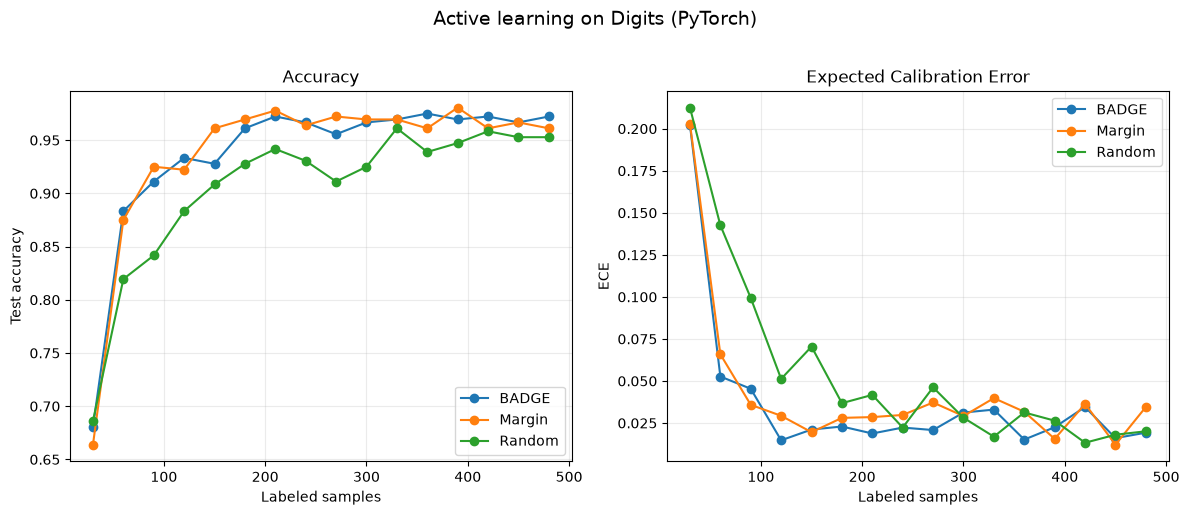

In [15]:
fig, (ax_acc, ax_ece) = plt.subplots(1, 2, figsize=(12, 5))

for name, data in results.items():
    ax_acc.plot(data["labeled_sizes"], data["accuracies"], marker="o", label=name)
    ax_ece.plot(data["labeled_sizes"], data["eces"], marker="o", label=name)

ax_acc.set_xlabel("Labeled samples")
ax_acc.set_ylabel("Test accuracy")
ax_acc.set_title("Accuracy")
ax_acc.legend()
ax_acc.grid(alpha=0.25)

ax_ece.set_xlabel("Labeled samples")
ax_ece.set_ylabel("ECE")
ax_ece.set_title("Expected Calibration Error")
ax_ece.legend()
ax_ece.grid(alpha=0.25)

fig.suptitle("Active learning on Digits (PyTorch)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()